# ✈️ NASA Turbofan Telemetry Analysis, Failure Prediction & Prescriptive RAG
### Multivariate Time-Series Exploratory Data Analysis, Degradation Modeling & Applied Prescriptive Intelligence
**Dataset**: NASA Ames Prognostics Center of Excellence — C-MAPSS (Commercial Modular Aero-Propulsion System Simulation)  
**Domain**: Commercial Aviation Powerplant Reliability Engineering & Predictive Maintenance (MRO)

---

## 📌 1. Project Background & Objective
In commercial aviation and heavy industrial systems, unscheduled component downtime (such as In-Flight Shutdowns - IFSD or Aircraft On Ground - AOG) costs millions of dollars and presents critical safety risks. 

This notebook conducts a complete, rigorous **Data Science and Machine Learning investigation** on multivariate sensor telemetry from 100 aircraft turbofan engines running from healthy initial states until failure:
1. **Exploratory Data Analysis (EDA)**: Sensor signal characteristics, zero-variance filtering, and engine lifetime distributions.
2. **Degradation Trajectory Analysis**: Observing physical wear signatures across key thermodynamic subsystems (Compressor pressure drop, Turbine temperature creep, Bypass ratio drift).
3. **Time-Series Feature Engineering**: Formulating rolling-window statistical signals and convolution-based linear degradation trends.
4. **Leakage-Free Grouped Validation**: Employing `GroupShuffleSplit` across engine units to guarantee zero cross-engine data leakage.
5. **Class-Balanced Machine Learning**: Predicting whether an engine is entering its critical failure window ($RUL \le 30$ flight cycles).
6. **Prescriptive Analytics via RAG**: Bridging statistical predictions with localized OEM Standard Operating Procedures (SOPs) to produce actionable maintenance work-orders.

In [1]:
import sys
from pathlib import Path

# Path setup
NOTEBOOK_DIR = Path.cwd().resolve()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
    accuracy_score,
    f1_score,
    recall_score,
    precision_score
)

# Plot styling
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 11
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

print(f"Project root resolved to: {PROJECT_ROOT}")

Project root resolved to: /Users/jatinpadmakarkulkarni/Desktop/projects/predictive-maintenance-mlops-main


## 📥 2. Data Ingestion & Schema Definition
The NASA CMAPSS dataset provides run-to-failure multivariate time series for 100 engines. Each record includes:
- `unit`: Engine identifier (1 to 100).
- `time_cycle`: Operational flight cycles logged.
- `setting1`, `setting2`, `setting3`: Operational regime settings.
- `sensor_1` to `sensor_21`: Thermodynamic and mechanical sensor measurements (temperatures, pressures, rotor speeds, coolant bleeds).

In [2]:
raw_data_path = PROJECT_ROOT / "data" / "01-raw" / "train_FD001.txt"

# CMAPSS schema definition (26 columns)
col_names = [
    "unit", "time_cycle",
    "setting1", "setting2", "setting3"
] + [f"sensor_{i}" for i in range(1, 22)]

df_raw = pd.read_csv(raw_data_path, sep=r"\s+", header=None, names=col_names)
print(f"Dataset Dimensions: {df_raw.shape[0]:,} rows (cycles) across {df_raw['unit'].nunique()} engines.")
print(f"Missing Values: {df_raw.isnull().sum().sum()}")
df_raw.head()

Dataset Dimensions: 20,631 rows (cycles) across 100 engines.
Missing Values: 0


,unit,time_cycle,setting1,setting2,setting3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## 🎯 3. Target Formulation: Remaining Useful Life (RUL) & Failure Window
Because each engine runs until failure in the training set:
$$\text{Max Cycle}_u = \max(\text{time\_cycle}_u)$$
$$\text{Remaining Useful Life (RUL)}_t = \text{Max Cycle}_u - \text{time\_cycle}_t$$

For predictive maintenance scheduling, airlines require an **early warning alert window**. We define the binary classification target:
$$\text{failure\_within\_30}_t = \begin{cases} 1 & \text{if } RUL_t \le 30 \\ 0 & \text{if } RUL_t > 30 \end{cases}$$

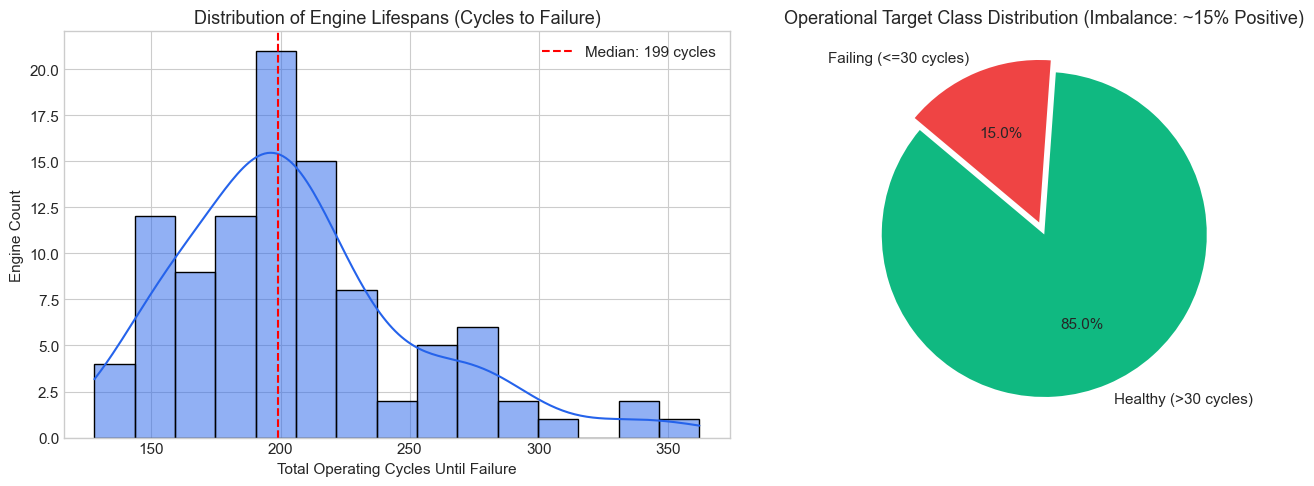

In [3]:
# Compute max cycle and RUL
max_cycles = df_raw.groupby("unit")["time_cycle"].max().reset_index()
max_cycles.columns = ["unit", "max_cycle"]
df_labeled = df_raw.merge(max_cycles, on="unit", how="left")
df_labeled["RUL"] = df_labeled["max_cycle"] - df_labeled["time_cycle"]
df_labeled["failure_within_30"] = (df_labeled["RUL"] <= 30).astype(int)

# Distribution of Engine Lifespans
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Lifespan histogram
sns.histplot(max_cycles["max_cycle"], kde=True, ax=axes[0], color="#2563EB", bins=15)
axes[0].set_title("Distribution of Engine Lifespans (Cycles to Failure)")
axes[0].set_xlabel("Total Operating Cycles Until Failure")
axes[0].set_ylabel("Engine Count")
axes[0].axvline(max_cycles["max_cycle"].median(), color="red", linestyle="--", label=f"Median: {max_cycles['max_cycle'].median():.0f} cycles")
axes[0].legend()

# Plot 2: Class Distribution
class_counts = df_labeled["failure_within_30"].value_counts()
colors = ["#10B981", "#EF4444"]
axes[1].pie(class_counts, labels=["Healthy (>30 cycles)", "Failing (<=30 cycles)"], autopct="%1.1f%%", colors=colors, startangle=140, explode=(0, 0.08))
axes[1].set_title("Operational Target Class Distribution (Imbalance: ~15% Positive)")

plt.tight_layout()
plt.show()

## 🔍 4. Sensor Signal Analysis & Constant Sensor Filtering
In real-world telemetry, sensors that register constant zero variance across all operating cycles provide zero discriminative signal and must be filtered to prevent unnecessary dimensionality.

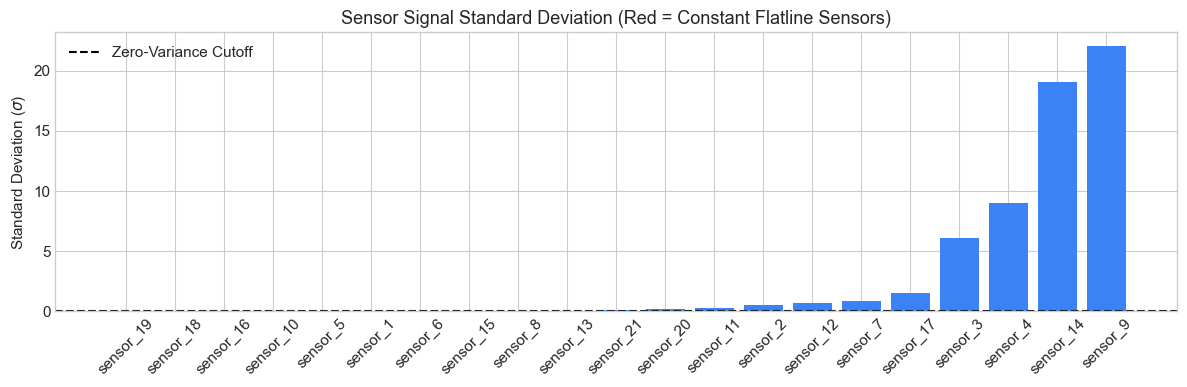

Constant Flatline Sensors (Dropped): ['sensor_19', 'sensor_18', 'sensor_16', 'sensor_10', 'sensor_5', 'sensor_1']
Informative Degradation Sensors Retained (15): ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


In [4]:
sensor_cols = [f"sensor_{i}" for i in range(1, 22)]
sensor_stds = df_labeled[sensor_cols].std().sort_values()

# Identify flatline sensors (std < 1e-4)
flatline_sensors = sensor_stds[sensor_stds < 1e-4].index.tolist()
informative_sensors = [s for s in sensor_cols if s not in flatline_sensors]

plt.figure(figsize=(12, 4))
bar_colors = ["#EF4444" if s in flatline_sensors else "#3B82F6" for s in sensor_stds.index]
plt.bar(sensor_stds.index, sensor_stds.values, color=bar_colors)
plt.axhline(1e-4, color="black", linestyle="--", label="Zero-Variance Cutoff")
plt.xticks(rotation=45)
plt.ylabel("Standard Deviation ($\\sigma$)")
plt.title("Sensor Signal Standard Deviation (Red = Constant Flatline Sensors)")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Constant Flatline Sensors (Dropped): {flatline_sensors}")
print(f"Informative Degradation Sensors Retained ({len(informative_sensors)}): {informative_sensors}")

## 📉 5. Physical Degradation Trajectories
Let us examine the lifetime trajectories of key informative thermodynamic sensors for Engine Unit #1:
- `sensor_11` (Static pressure at High Pressure Compressor outlet)
- `sensor_4` (Total temperature at Low Pressure Turbine outlet)
- `sensor_15` (Bypass ratio)
- `sensor_9` (Physical core speed)

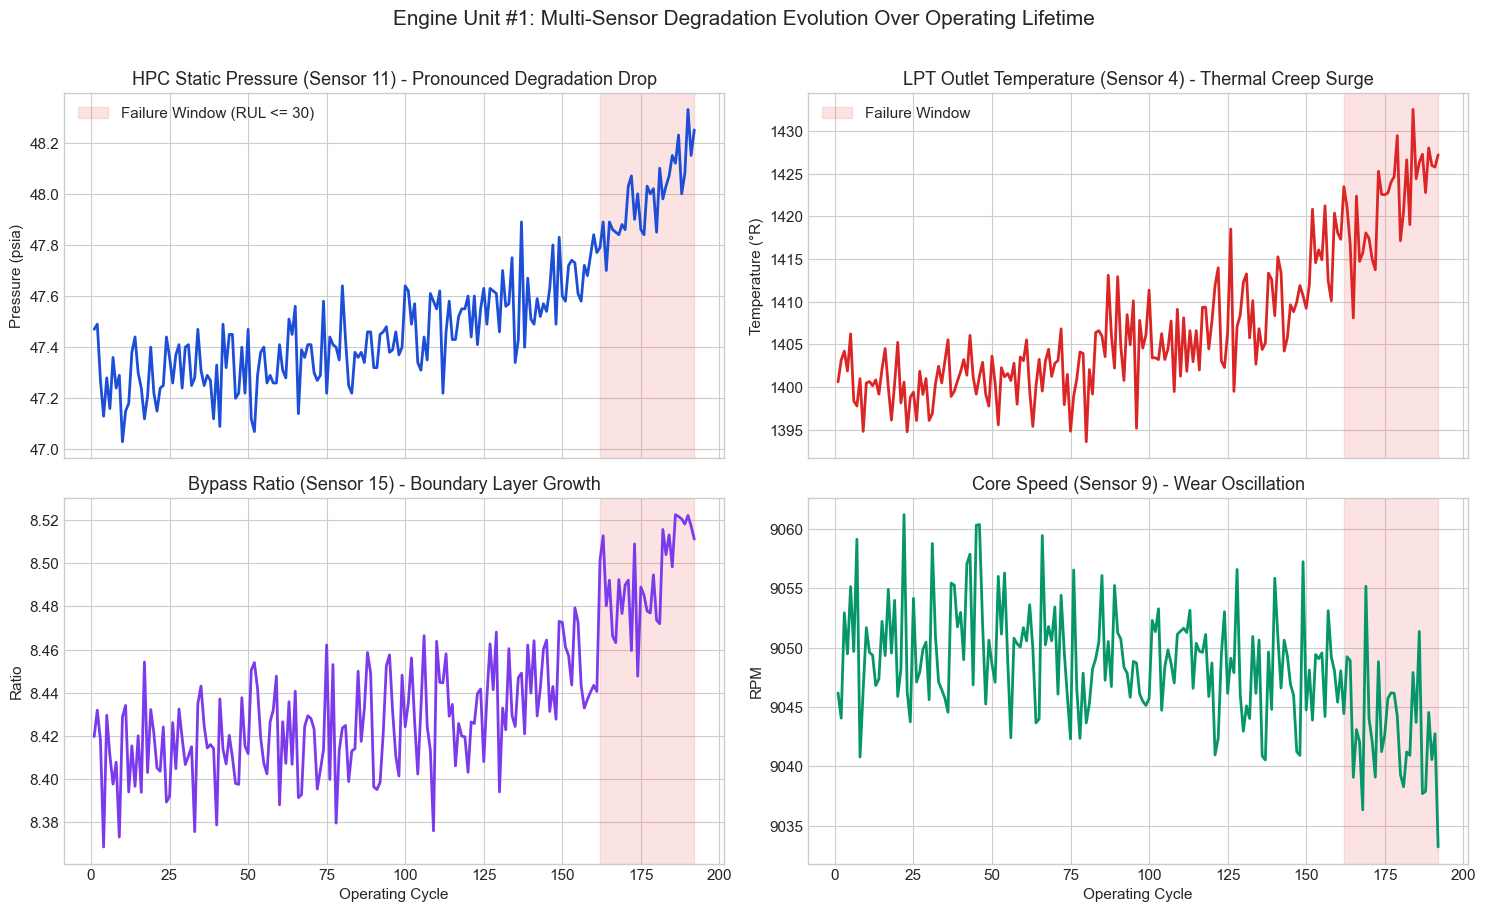

In [5]:
sample_unit = 1
unit_df = df_labeled[df_labeled["unit"] == sample_unit].copy()
cutoff_cycle = unit_df["time_cycle"].max() - 30

fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True)

# Sensor 11: HPC Static Pressure
axes[0, 0].plot(unit_df["time_cycle"], unit_df["sensor_11"], color="#1D4ED8", lw=2)
axes[0, 0].axvspan(cutoff_cycle, unit_df["time_cycle"].max(), color="#EF4444", alpha=0.15, label="Failure Window (RUL <= 30)")
axes[0, 0].set_title("HPC Static Pressure (Sensor 11) - Pronounced Degradation Drop")
axes[0, 0].set_ylabel("Pressure (psia)")
axes[0, 0].legend()

# Sensor 4: LPT Outlet Temperature
axes[0, 1].plot(unit_df["time_cycle"], unit_df["sensor_4"], color="#DC2626", lw=2)
axes[0, 1].axvspan(cutoff_cycle, unit_df["time_cycle"].max(), color="#EF4444", alpha=0.15, label="Failure Window")
axes[0, 1].set_title("LPT Outlet Temperature (Sensor 4) - Thermal Creep Surge")
axes[0, 1].set_ylabel("Temperature (°R)")
axes[0, 1].legend()

# Sensor 15: Bypass Ratio
axes[1, 0].plot(unit_df["time_cycle"], unit_df["sensor_15"], color="#7C3AED", lw=2)
axes[1, 0].axvspan(cutoff_cycle, unit_df["time_cycle"].max(), color="#EF4444", alpha=0.15)
axes[1, 0].set_title("Bypass Ratio (Sensor 15) - Boundary Layer Growth")
axes[1, 0].set_ylabel("Ratio")
axes[1, 0].set_xlabel("Operating Cycle")

# Sensor 9: Core Speed
axes[1, 1].plot(unit_df["time_cycle"], unit_df["sensor_9"], color="#059669", lw=2)
axes[1, 1].axvspan(cutoff_cycle, unit_df["time_cycle"].max(), color="#EF4444", alpha=0.15)
axes[1, 1].set_title("Core Speed (Sensor 9) - Wear Oscillation")
axes[1, 1].set_ylabel("RPM")
axes[1, 1].set_xlabel("Operating Cycle")

plt.suptitle(f"Engine Unit #{sample_unit}: Multi-Sensor Degradation Evolution Over Operating Lifetime", y=1.01, fontsize=15)
plt.tight_layout()
plt.show()

## 📊 6. Sensor Correlation & Multicollinearity Heatmap
We examine the Pearson correlation between informative sensors and Remaining Useful Life (RUL). Strong negative correlations indicate sensors that rise as the engine degrades; strong positive correlations indicate sensors that drop.

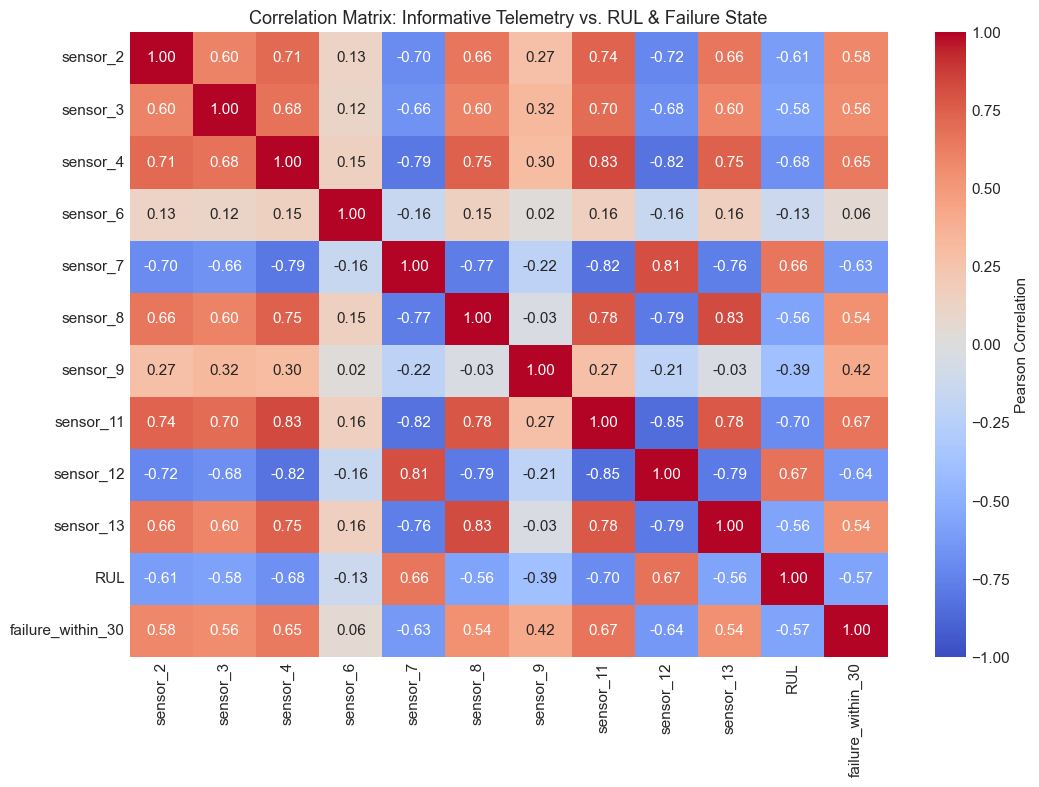

In [6]:
corr_cols = informative_sensors[:10] + ["RUL", "failure_within_30"]
corr_matrix = df_labeled[corr_cols].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, cbar_kws={"label": "Pearson Correlation"})
plt.title("Correlation Matrix: Informative Telemetry vs. RUL & Failure State")
plt.tight_layout()
plt.show()

## ⚙️ 7. Time-Series Feature Engineering
Raw instantaneous sensor readings fluctuate with measurement noise. To capture physical wear dynamics, we engineer:
1. **Rolling Statistics**: Mean, Standard Deviation, Min, and Max over windows of 5, 10, and 20 cycles.
2. **Linear Degradation Trends**: The rate of change (slope) computed via 1D convolution over a 20-cycle sliding window.

This yields a feature matrix of **297 domain-engineered features**.

In [7]:
from src.pipelines.feature_pipeline import generate_features

print("Executing vectorized feature generation...")
df_features = generate_features(df_labeled)
print(f"Generated Feature Matrix Shape: {df_features.shape}")

drop_cols = {"unit", "time_cycle", "max_cycle", "RUL", "failure_within_30"}
feature_names = [c for c in df_features.columns if c not in drop_cols]
print(f"Total Model Features: {len(feature_names)}")

Executing vectorized feature generation...


Generated Feature Matrix Shape: (20631, 302)
Total Model Features: 297


## 🛡️ 8. Leakage-Free Validation Strategy: GroupShuffleSplit
### Why standard random train/test split fails in time-series predictive maintenance:
If cycles are shuffled randomly across rows, cycles from the same engine unit appear in both training and test sets. Telemetry from cycle $t$ leaks information about cycle $t+1$, causing **catastrophic temporal leakage** and inflated, unrealistic test scores.

**Industry Standard Solution**: `GroupShuffleSplit` by `unit`. 
- 80 engines are used strictly for training (~16,500 cycles).
- 20 complete engines are held out exclusively for validation (~4,070 cycles).

In [8]:
X = df_features[feature_names].copy()
y = df_features["failure_within_30"].values
groups = df_features["unit"].values

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, val_idx = next(gss.split(X, y, groups=groups))

train_units = np.unique(groups[train_idx])
val_units = np.unique(groups[val_idx])

print(f"Training Engines ({len(train_units)} units): {train_units[:10]}...")
print(f"Held-out Validation Engines ({len(val_units)} units): {val_units}")
print(f"Train cycles: {len(train_idx):,} | Validation cycles: {len(val_idx):,}")

# Preprocessing fitted strictly on training engines
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_train = scaler.fit_transform(pd.DataFrame(imputer.fit_transform(X.iloc[train_idx]), columns=feature_names))
X_val = scaler.transform(pd.DataFrame(imputer.transform(X.iloc[val_idx]), columns=feature_names))

y_train = y[train_idx]
y_val = y[val_idx]

Training Engines (80 units): [ 2  3  4  6  7  8  9 10 12 14]...
Held-out Validation Engines (20 units): [ 1  5 11 13 19 23 31 32 34 40 45 46 54 71 74 77 78 81 84 91]
Train cycles: 16,561 | Validation cycles: 4,070


## 🤖 9. Model Training & Rigorous Evaluation
We train a class-balanced `RandomForestClassifier` and evaluate precision, recall, F1-score, ROC-AUC, and PR-AUC on the held-out validation engines.

=== HELD-OUT VALIDATION CLASSIFICATION REPORT ===
                 precision    recall  f1-score   support

 Healthy (>30c)     0.9852    0.9814    0.9833      3450
Failing (<=30c)     0.8989    0.9177    0.9082       620

       accuracy                         0.9717      4070
      macro avg     0.9420    0.9496    0.9458      4070
   weighted avg     0.9720    0.9717    0.9719      4070



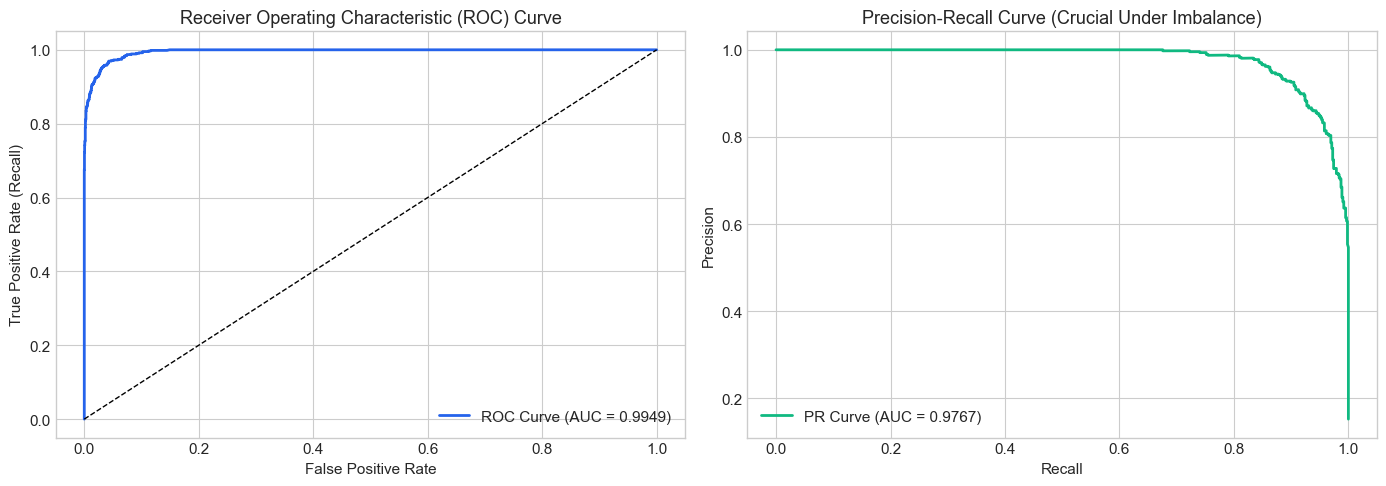

In [9]:
rf = RandomForestClassifier(
    n_estimators=150,
    max_depth=12,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_val)
y_prob = rf.predict_proba(X_val)[:, 1]

print("=== HELD-OUT VALIDATION CLASSIFICATION REPORT ===")
print(classification_report(y_val, y_pred, target_names=["Healthy (>30c)", "Failing (<=30c)"], digits=4))

# Evaluation Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC Curve
fpr, tpr, _ = roc_curve(y_val, y_prob)
roc_auc = roc_auc_score(y_val, y_prob)
axes[0].plot(fpr, tpr, color="#2563EB", lw=2, label=f"ROC Curve (AUC = {roc_auc:.4f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_title("Receiver Operating Characteristic (ROC) Curve")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].legend(loc="lower right")

# PR Curve
precision_curve, recall_curve, _ = precision_recall_curve(y_val, y_prob)
pr_auc = average_precision_score(y_val, y_prob)
axes[1].plot(recall_curve, precision_curve, color="#10B981", lw=2, label=f"PR Curve (AUC = {pr_auc:.4f})")
axes[1].set_title("Precision-Recall Curve (Crucial Under Imbalance)")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="lower left")

plt.tight_layout()
plt.show()

## 🏆 10. Confusion Matrix & Physical Feature Importances

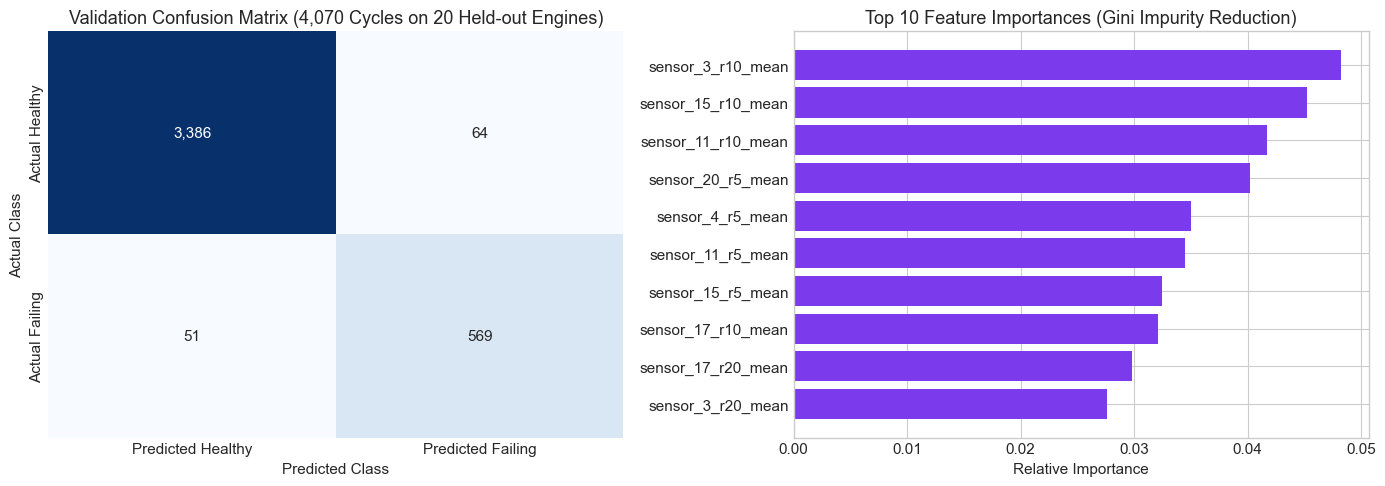

Top 5 Most Informative Degradation Features:
 - sensor_3_r10_mean: 0.0482
 - sensor_15_r10_mean: 0.0452
 - sensor_11_r10_mean: 0.0417
 - sensor_20_r5_mean: 0.0402
 - sensor_4_r5_mean: 0.0350


In [10]:
cm = confusion_matrix(y_val, y_pred)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion matrix heatmap
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["Predicted Healthy", "Predicted Failing"],
            yticklabels=["Actual Healthy", "Actual Failing"])
axes[0].set_title("Validation Confusion Matrix (4,070 Cycles on 20 Held-out Engines)")
axes[0].set_ylabel("Actual Class")
axes[0].set_xlabel("Predicted Class")

# Top feature importances
fi_df = pd.DataFrame({"feature": feature_names, "importance": rf.feature_importances_}).sort_values("importance", ascending=False)
top_fi = fi_df.head(10).sort_values("importance", ascending=True)

axes[1].barh(top_fi["feature"], top_fi["importance"], color="#7C3AED")
axes[1].set_title("Top 10 Feature Importances (Gini Impurity Reduction)")
axes[1].set_xlabel("Relative Importance")

plt.tight_layout()
plt.show()

print("Top 5 Most Informative Degradation Features:")
for idx, row in fi_df.head(5).iterrows():
    print(f" - {row['feature']}: {row['importance']:.4f}")

## 🛠️ 11. Prescriptive Analytics via RAG (Applied Retrieval-Augmented Generation)
### From Prediction to Prescription
In industrial operations, knowing an engine has an $88\%$ failure probability is insufficient. Maintenance engineers need:
1. **Root-Cause Subsystem Diagnosis**: What is degrading (HPC vs. LPT)?
2. **OEM Technical Orders & SOPs**: Exact step-by-step FAA/EASA-compliant maintenance procedure.
3. **Bill of Materials (BOM)**: What replacement parts and tooling are required?

Here we demonstrate the lightweight, localized **BM25 RAG Maintenance Copilot** connecting ML telemetry alerts to OEM Standard Operating Procedures.

In [11]:
from src.rag.engine import MaintenanceCopilot

copilot = MaintenanceCopilot()

# Simulate an alert on Engine #12 approaching failure with depressed HPC pressure and elevated LPT temperature
alert_factors = [
    {"sensor": "sensor_11", "deviation_direction": "DEPRESSED", "severity": "HIGH"},
    {"sensor": "sensor_4", "deviation_direction": "ELEVATED", "severity": "HIGH"}
]

work_order = copilot.generate_work_order(
    unit_id=12,
    cycle=175,
    failure_risk=0.884,
    risk_level="CRITICAL",
    degrading_factors=alert_factors
)

print(f"Generated Work Order: {work_order['work_order_id']}")
print(f"Dispatch Priority:   {work_order['dispatch_priority']}")
print(f"Diagnostic Summary:  {work_order['telemetry_summary']}")
print("\nMatched OEM Standard Operating Procedures:")
for sop in work_order["matched_sops"]:
    print(f" - [{sop['doc_id']}] {sop['title']} (Subsystem: {sop['subsystem']}, Relevance: {sop['relevance_score']})")

print("\nField Technician Action Checklist:")
for step in work_order["mandatory_action_checklist"][:4]:
    print(f" [ ] {step}")

print("\nRecommended Replacement Parts:")
for part in work_order["recommended_parts"]:
    print(f" • {part['part_name']} ({part['part_number']})")

Generated Work Order: WO-CMAPSS-U012-C175
Dispatch Priority:   P1 - IMMEDIATE_AOG (AIRCRAFT ON GROUND)
Diagnostic Summary:  Engine Unit #12 evaluated at Cycle 175. ML Model predicts 88.4% risk of failure within 30 flight cycles. Primary degraded telemetry indicators: sensor_11 (DEPRESSED), sensor_4 (ELEVATED).

Matched OEM Standard Operating Procedures:
 - [SOP-EMERG-9901] Critical RUL Exhaustion & Immediate Aircraft On Ground (AOG) Overhaul Protocol (Subsystem: Entire Turbofan Powerplant, Relevance: 5.65)
 - [SOP-HPC-7201] High Pressure Compressor (HPC) Static Pressure Loss & Tip Clearance Degradation (Subsystem: High Pressure Compressor (HPC), Relevance: 2.828)

Field Technician Action Checklist:
 [ ] Step 1: Ground powerplant immediately upon landing; log engine serial number into AOG priority registry.
 [ ] Step 2: Quarantine oil filter and chip detector plugs for spectrometric oil analysis (SOAP).
 [ ] Step 3: Disconnect quick engine change (QEC) harness and prepare engine for rem

### Interactive Technical Knowledge Base Query
Engineers can also query the RAG assistant with natural language maintenance questions:

In [12]:
query = "What are the inspection steps when static pressure at HPC outlet drops below 47 psia?"
response = copilot.answer_query(query)

print(f"Query: {response['query']}\n")
print(response['answer'])
print("\nCitations:")
for cite in response['citations']:
    print(f" • {cite}")

Query: What are the inspection steps when static pressure at HPC outlet drops below 47 psia?

**Diagnostic Summary (SOP-HPC-7201)**:
- **Subsystem**: High Pressure Compressor (HPC)
- **Key Telemetry Triggers**: sensor_11: Static pressure at HPC outlet drops below 47.0 psia (nominal 47.2 - 47.6 psia), sensor_3: Total pressure at HPC outlet drops under 1580.0 psia, sensor_7: Total pressure at HPC outlet shows negative trend slope
- **Likely Causes**: Axial compressor blade tip rub and aerodynamic erosion causing excessive clearance; Fouling of stator vanes from airborne particulates and particulate ingestion; Variable Stator Vane (VSV) actuator mechanical hysteresis

**Recommended Field Protocol**:
  Step 1: Perform 4-stage borescope inspection through port S3 and S4 to inspect HPC rotor blades for leading-edge pitting.
  Step 2: Measure rotor blade-to-casing tip clearance using optical feeler gauge. Threshold limit: 0.045 inches.
  Step 3: Execute full compressor core wash using deminer